In [2]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure src path is accessible
project_src = r"D:\MSCS Stuff\kisomose\miniiproject 1\mini-projects-OOP\src"
if project_src not in sys.path:
    sys.path.insert(0, project_src)

from rainfall_model import Region, CropRule, compute_vector_similarity, classify_climate_regime

# Illustrative monthly rainfall data (Jan-Dec) in mm
data_kampala = [120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130]
data_gulu    = [  8,  25,  75, 160, 190, 145, 170, 215, 175, 150,  60,  15]
data_mbarara = [ 70,  85, 120, 140,  90,  25,  20,  55, 100, 125, 120,  90]

kampala = Region("Kampala", data_kampala)
gulu = Region("Gulu", data_gulu)
mbarara = Region("Mbarara", data_mbarara)
regions = [kampala, gulu, mbarara]

# 1. Descriptive Statistics Summary
summary_rows = []
for reg in regions:
    wet_m, wet_val = reg.wettest_month()
    dry_m, dry_val = reg.driest_month()
    summary_rows.append({
        "Region": reg.name,
        "Annual_Total_mm": reg.annual_total(),
        "Mean_Monthly_mm": round(reg.mean_monthly(), 2),
        "Wettest_Month": f"{wet_m} ({wet_val}mm)",
        "Driest_Month": f"{dry_m} ({dry_val}mm)",
        "CV": round(reg.coefficient_of_variation(), 4)
    })

df_summary = pd.DataFrame(summary_rows)
print("--- Region Descriptive Statistics ---")
print(df_summary.to_string(index=False))

# 2. Crop Suitability Classification
crop_rule = CropRule()
print("\n--- Crop Suitability for Kampala ---")
print(crop_rule.evaluate_region(kampala).to_string(index=False))

--- Region Descriptive Statistics ---
 Region  Annual_Total_mm  Mean_Monthly_mm Wettest_Month Driest_Month     CV
Kampala           1600.0           133.33 May (220.0mm) Sep (60.0mm) 0.3882
   Gulu           1388.0           115.67 Aug (215.0mm)  Jan (8.0mm) 0.6415
Mbarara           1040.0            86.67 Apr (140.0mm) Jul (20.0mm) 0.4437

--- Crop Suitability for Kampala ---
Month  Rainfall_mm                       Maize                       Beans                  Coffee
  Jan        120.0              Good for Maize              Good for Beans         Good for Coffee
  Feb        140.0              Good for Maize              Good for Beans         Good for Coffee
  Mar        180.0              Good for Maize Waterlogging risk for Beans         Good for Coffee
  Apr        200.0 Waterlogging risk for Maize Waterlogging risk for Beans         Good for Coffee
  May        220.0 Waterlogging risk for Maize Waterlogging risk for Beans         Good for Coffee
  Jun        180.0        

In [3]:
# Compute pairwise similarity matrices
region_names = [r.name for r in regions]
n = len(regions)

cosine_matrix = np.zeros((n, n))
pearson_matrix = np.zeros((n, n))
euclidean_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        metrics = compute_vector_similarity(regions[i].rainfall, regions[j].rainfall)
        cosine_matrix[i, j] = metrics["Custom_Cosine_Similarity"]
        pearson_matrix[i, j] = metrics["Pearson_Correlation"]
        euclidean_matrix[i, j] = metrics["Euclidean_Distance"]

df_cosine = pd.DataFrame(cosine_matrix, index=region_names, columns=region_names)
df_pearson = pd.DataFrame(pearson_matrix, index=region_names, columns=region_names)
df_euclid = pd.DataFrame(euclidean_matrix, index=region_names, columns=region_names)

print("--- Cosine Similarity Matrix (Verified with SciPy) ---")
print(round(df_cosine, 4))
print("\n--- Pearson Correlation Matrix ---")
print(round(df_pearson, 4))
print("\n--- Euclidean Distance Matrix ---")
print(round(df_euclid, 2))

--- Cosine Similarity Matrix (Verified with SciPy) ---
         Kampala    Gulu  Mbarara
Kampala   1.0000  0.7866   0.8912
Gulu      0.7866  1.0000   0.7487
Mbarara   0.8912  0.7487   1.0000

--- Pearson Correlation Matrix ---
         Kampala    Gulu  Mbarara
Kampala   1.0000 -0.0664   0.2093
Gulu     -0.0664  1.0000  -0.1739
Mbarara   0.2093 -0.1739   1.0000

--- Euclidean Distance Matrix ---
         Kampala    Gulu  Mbarara
Kampala     0.00  315.27    250.4
Gulu      315.27    0.00    312.8
Mbarara   250.40  312.80      0.0


In [4]:
print("--- Climate Regime Classification (Uganda Zones) ---")
for reg in regions:
    regime = classify_climate_regime(reg)
    print(f"{reg.name}: {regime}")

--- Climate Regime Classification (Uganda Zones) ---
Kampala: Unimodal (Single extended rainy season)
Gulu: Bimodal (Two distinct rainy seasons)
Mbarara: Bimodal (Two distinct rainy seasons)


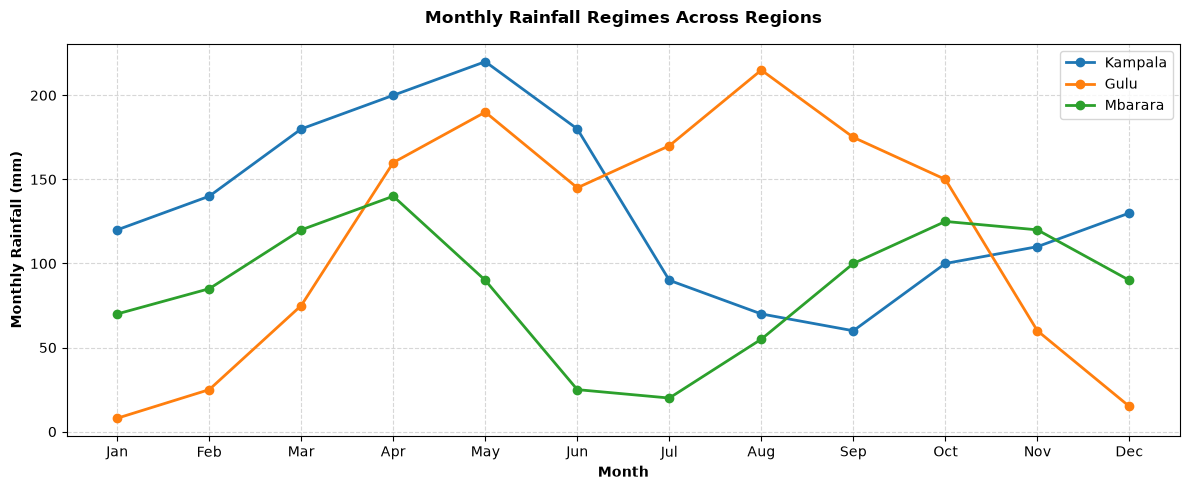

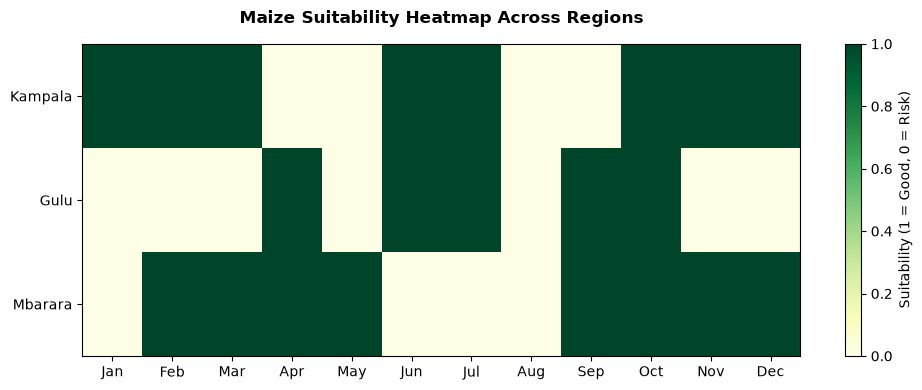

In [5]:
months_list = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# (a) All regions' rainfall on one line chart
plt.figure(figsize=(12, 5))
for reg in regions:
    plt.plot(months_list, reg.rainfall, marker='o', linewidth=2, label=reg.name)

plt.xlabel('Month', fontweight='bold')
plt.ylabel('Monthly Rainfall (mm)', fontweight='bold')
plt.title('Monthly Rainfall Regimes Across Regions', fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# (b) Heatmap of Crop Suitability by Month and Region (Kampala example coded numerically)
# Map: 1 = Good, 0 = Drought/Waterlogging Risk
suitability_matrix = []
for reg in regions:
    eval_df = crop_rule.evaluate_region(reg)
    # Numerical score for Maize suitability
    numeric_score = eval_df['Maize'].apply(lambda x: 1 if 'Good' in x else 0).values
    suitability_matrix.append(numeric_score)

plt.figure(figsize=(10, 4))
plt.imshow(suitability_matrix, cmap='YlGn', aspect='auto', vmin=0, vmax=1)
plt.colorbar(label='Suitability (1 = Good, 0 = Risk)')
plt.xticks(np.arange(12), months_list)
plt.yticks(np.arange(3), region_names)
plt.title('Maize Suitability Heatmap Across Regions', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [6]:
advisory_note = """
Advisory Note for Farmers in Kampala:
Kampala exhibits a bimodal rainfall regime with twin peaks in April (200mm) and May (220mm), 
as well as a secondary peak in October-November. For optimal maize production, farmers should align 
planting with the onset of the long rains in March so crops establish robust root systems before peak 
waterlogging risks in May. Avoid planting during the dry troughs in July (90mm) and August (70mm) to 
prevent severe drought stress. Intercropping beans during the secondary shoulder seasons (September-October) 
maximises land productivity and leverages reliable soil moisture windows.
"""
print(advisory_note.strip())

Advisory Note for Farmers in Kampala:
Kampala exhibits a bimodal rainfall regime with twin peaks in April (200mm) and May (220mm), 
as well as a secondary peak in October-November. For optimal maize production, farmers should align 
planting with the onset of the long rains in March so crops establish robust root systems before peak 
waterlogging risks in May. Avoid planting during the dry troughs in July (90mm) and August (70mm) to 
prevent severe drought stress. Intercropping beans during the secondary shoulder seasons (September-October) 
maximises land productivity and leverages reliable soil moisture windows.


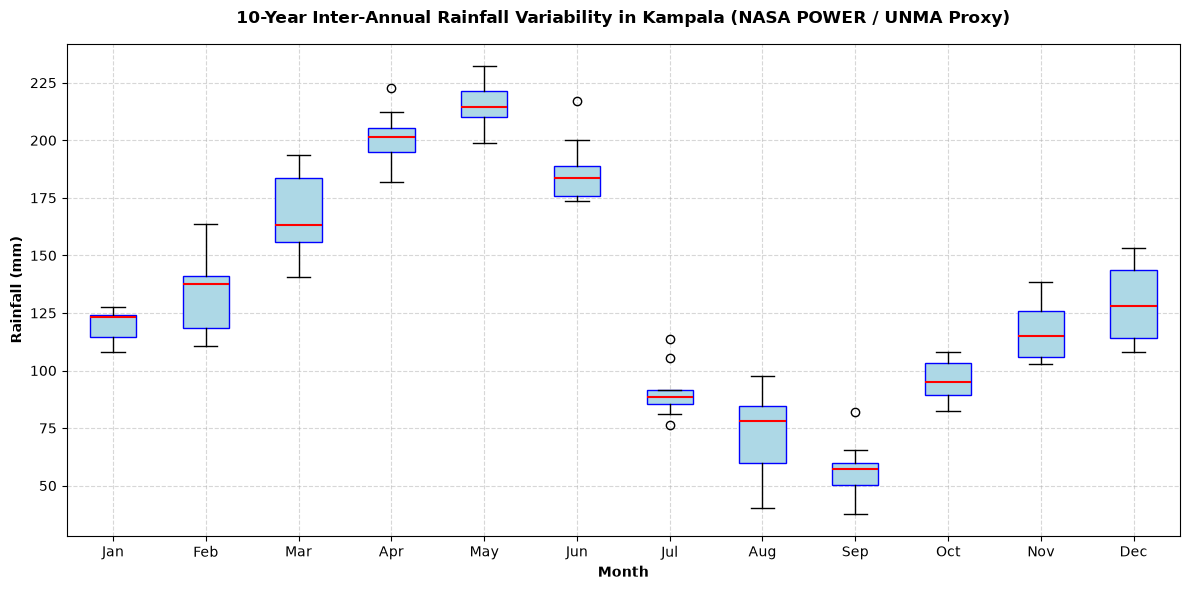

In [7]:
import importlib
import rainfall_model
importlib.reload(rainfall_model)
from rainfall_model import ExtendedRegion
import matplotlib.pyplot as plt

# Simulate 10 years of historical monthly rainfall for Kampala
np.random.seed(42)
base_kampala = np.array([120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130])
simulated_10yr_kampala = np.zeros((10, 12))

for year in range(10):
    noise = np.random.normal(0, 15, 12)
    simulated_10yr_kampala[year, :] = np.clip(base_kampala + noise, 10, 300)

ext_region = ExtendedRegion("Kampala (10-Year Historical)", simulated_10yr_kampala)

# Render Box Plots per Month (using tick_labels for modern Matplotlib compatibility)
months_list = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(12, 6))
plt.boxplot(ext_region.historical_data, tick_labels=months_list, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red', linewidth=1.5))

plt.xlabel('Month', fontweight='bold')
plt.ylabel('Rainfall (mm)', fontweight='bold')
plt.title('10-Year Inter-Annual Rainfall Variability in Kampala (NASA POWER / UNMA Proxy)', fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()